<a href="https://colab.research.google.com/github/cherissaiteriteka32-netizen/CraftHub-project/blob/master/AI_Basics_From_LSTMs_to_Transformers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Artificial Intelligence Basics  
## **FROM LSTMs TO TRANSFORMERS**
### A guided, visual and practical introduction to attention and generative AI

**Year 2 | BSc Computer Science & BSc Data Science**  
**Tutorials 15, 16, 17 and 18 | Uganda Christian University**

> **The big question:** We trained an LSTM to predict the next note in a melody. How do we move from that to a model that can read a passage, answer questions, write text and produce code?

This notebook is a *teaching laboratory*, not just a collection of commands. Read the explanation **before** running each code cell. You are not expected to know Transformers, vector algebra, tokenization, PyTorch or the Hugging Face library in advance. Every important new concept is explained as it appears.

**What you will accomplish:**
1. Explain the difference between recurrent memory and attention.
2. Understand tokenization, embeddings, Query–Key–Value and softmax.
3. Calculate a small attention example with Python, and interpret its heatmap.
4. Explain positional information, multi-head attention and causal masking.
5. Use a pretrained Transformer to answer questions from a passage.
6. Use a generative Transformer to create text and basic code.
7. Distinguish impressive model output from verified or reliable output.

**Suggested pace:** 2–3 hours of guided teaching, or more for independent study. There are *Prediction*, *Try it* and *Explain* activities throughout. At the end you will find review questions and a practical challenge.

**Important distinction:** The teaching illustrations are labelled as illustrations. Real model predictions are produced only by the model-running cells. Never confuse a pretty attention diagram with proof of what a trained model has actually learned.

### Before you start: the terms we will use

| Term | Plain-language meaning |
|---|---|
| **Sequence** | Items whose order matters: words in a sentence, notes in music or sensor readings over time. |
| **Token** | A unit the language model processes. One token can be a word, part of a word, punctuation or another text fragment. |
| **Vector** | A short list of numbers, e.g., `[0.2, -0.4, 0.8]`. Models use many such numbers to represent patterns. |
| **Parameter (weight)** | A number the model learned during training. |
| **Pretrained model** | A model whose weights were trained previously, before our notebook runs. |
| **Inference** | Using trained weights to produce an output. Inference does not normally update model weights. |
| **Context** | Information supplied or made available to a model when it produces an output. |

**Not all code needs to be understood at the same depth.** We will write and inspect the central attention calculation. Drawing-library code and pretrained-model loading can initially be treated as tools. You will still learn what their inputs and outputs mean.

### How to use Google Colab
1. Open this `.ipynb` in **Google Colab**.
2. From **Runtime → Change runtime type**, choose a **T4 GPU** if available. A GPU is recommended for the language-generation section; the earlier sections also run on CPU.
3. Run cells **from the top down** using the play button. Later cells rely on objects created earlier.
4. When a cell has a variable marked **CHANGE ME**, edit that variable and run the cell again.
5. When using a pretrained model for the first time, Colab downloads its weights. **Internet access is required** for these downloads.

**Troubleshooting:** If Colab disconnects or you restart the runtime, rerun the setup cell and the cells needed for your current section. If you see `NameError`, a previous cell was probably skipped. Model loading can fail due to temporary network availability or GPU memory; the practical includes a CPU alternative.

---
# SECTION 0 - Prepare the laboratory

The first cells install a few libraries, check hardware and define the drawing tools used by the illustrations. You do **not** need to learn the graphics code to understand Transformers.

In [46]:
# Run once at the beginning. Google Colab already includes torch, numpy and matplotlib.
# We restrict Transformers to major version 4 for consistent support of the
# question-answering pipeline used later in this teaching notebook.
%pip -q install "transformers>=4.45,<5" "accelerate>=0.33" "sentencepiece>=0.2.0"

In [45]:
import sys
import torch
import numpy as np
from IPython.display import display, HTML

np.set_printoptions(precision=3, suppress=True)
np.random.seed(7)
torch.manual_seed(7)
print('Python:', sys.version.split()[0])
print('PyTorch:', torch.__version__)
print('GPU available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU model:', torch.cuda.get_device_name(0))
else:
    print('CPU mode: all numeric and reading experiments work; generation uses a lighter model.')

Python: 3.13.16
PyTorch: 2.11.0+cu130
GPU available: True
GPU model: Tesla T4


**Drawing tools.** This longer cell contains reusable functions for producing the diagrams. Its only job is presentation. Read on after running it: the scientific calculations begin in Section 3. If your notebook viewer collapses the cell, you may leave it collapsed.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Circle
from IPython.display import display, HTML

NAVY='#14243a'; BLUE='#2b5e93'; TEAL='#008e87'; GOLD='#de9e39'; RED='#c95458'
PALE='#eef4f9'; GREY='#53667e'; INK='#243247'
plt.rcParams.update({'figure.dpi':120,'font.family':'DejaVu Sans','font.size':10,
                     'axes.spines.top':False,'axes.spines.right':False})

def _board(title, subtitle='', h=4.0):
    fig,ax=plt.subplots(figsize=(11,h),facecolor='white')
    ax.set_xlim(0,11);ax.set_ylim(0,h);ax.axis('off')
    fig.text(.065,.955,title,fontsize=16,fontweight='bold',color=NAVY,va='top')
    if subtitle: fig.text(.065,.88,subtitle,fontsize=9.5,color=GREY,va='top')
    return fig,ax

def _box(ax,x,y,w,h,s,face=PALE,edge=None,fs=10,color=INK):
    patch=FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.08,rounding_size=0.12',
                         linewidth=1,edgecolor=edge or face,facecolor=face)
    ax.add_patch(patch)
    ax.text(x+w/2,y+h/2,s,ha='center',va='center',fontsize=fs,color=color,linespacing=1.25)

def _arrow(ax,start,end,color=BLUE,rad=0,lw=1.9,style='-|>'):
    ax.add_patch(FancyArrowPatch(start,end,arrowstyle=style,mutation_scale=13,
                                 connectionstyle=f'arc3,rad={rad}',lw=lw,color=color))

def diagram(name):
    """Draw a conceptual teaching diagram. The diagrams are explanatory, not model-derived outputs."""
    if name=='journey':
        fig,ax=_board('ONE BIG STORY  |  from sequences to generative AI',
                      'We will understand the reason for each new idea before using real models.',4.0)
        blocks=[('1','RNN','Carry a hidden state'),('2','LSTM','Control memory with gates'),
                ('3','Transformer','Attend across tokens'),('4','Generative AI','Produce new content')]
        for i,(n,t,s) in enumerate(blocks):
            x=.3+2.78*i; face=[PALE,'#e6f1f6','#dbf3ed','#fcf1dd'][i]
            _box(ax,x,1.15,2.25,1.6,f'{n}  {t}\n\n{s}',face=face,fs=9)
            if i<3:_arrow(ax,(x+2.32,1.95),(x+2.66,1.95),TEAL)
        ax.text(5.5,.45,'Sequence prediction links all four; models differ in mechanism, representation and scale.',
                ha='center',fontsize=10,color=GREY)
    elif name=='sequence':
        fig,ax=_board('WHY CHANGE THE ARCHITECTURE?',
                      'The visual compares information paths, not a measured accuracy result.',5)
        labels=['The','student','studied','all','night','because','she','had','a','test']
        for i,t in enumerate(labels):
            x=.35+i*1.05
            _box(ax,x,3.16,.75,.45,t,face='#e7eff8',fs=8)
            if i<9:_arrow(ax,(x+.8,3.39),(x+1.02,3.39),BLUE,lw=1.2)
        ax.text(.38,4.1,'LSTM: information flows through successive recurrent steps',fontsize=11,color=NAVY,weight='bold')
        for i,t in enumerate(labels):
            x=.35+i*1.05
            _box(ax,x,1.32,.75,.45,t,face='#e0f2ed',fs=8)
        _arrow(ax,(1.7,1.82),(7.1,1.82),TEAL,rad=-.17,lw=2.8)
        _arrow(ax,(2.8,1.82),(7.1,1.82),TEAL,rad=-.06,lw=1.3)
        ax.text(.38,2.62,'Transformer: a token can directly combine information from permitted positions',fontsize=11,color=NAVY,weight='bold')
        ax.text(5.5,.55,'Attention does not eliminate sequence order: positional information is still needed.',ha='center',fontsize=9.5,color=GREY)
    elif name=='reference':
        fig,ax=_board('A WORD CAN DEPEND ON AN EARLIER WORD',
                      'Ask: to whom does “she” refer? The arrows show a plausible relationship, not learned weights.',3.7)
        words=['The','student','submitted','the','assignment','because','she','finished','.']
        widths=[.7,1.2,1.35,.65,1.45,1.2,.7,1.1,.35]
        x=.3; centers=[]
        for t,w in zip(words,widths):
            _box(ax,x,1.25,w,.65,t,face='#e7f2f8' if t!='she' else '#dff3ee',fs=11)
            centers.append(x+w/2);x+=w+.12
        _arrow(ax,(centers[6],2.05),(centers[1],2.05),TEAL,rad=-.43,lw=3)
        ax.text(5.5,.45,'The association is suggested by context; attention weights need not map neatly to grammar.',
                ha='center',color=GREY,fontsize=9.5)
    elif name=='tokens':
        fig,ax=_board('FROM LANGUAGE TO NUMBERS',
                      'A tokenizer produces token IDs; an embedding table produces vectors.',4.5)
        samples=[('The',103),('student',2153),('opened',10298),('the',1996),('book',2338)]
        for i,(t,token_id) in enumerate(samples):
            x=.6+2.12*i
            _box(ax,x,3.05,1.5,.45,t,'#e6f2f8',fs=11)
            _arrow(ax,(x+.75,2.99),(x+.75,2.57),BLUE)
            _box(ax,x,2.02,1.5,.45,str(token_id),'#f8efd9',fs=11)
            _arrow(ax,(x+.75,1.96),(x+.75,1.55),TEAL)
            _box(ax,x,1.04,1.5,.45,f'[{i/10:.1f}, {(.8-i*.11):.2f}, …]','#e4f2ed',fs=9)
        ax.text(5.5,.42,'Example IDs and vectors are invented for explanation; real tokenizer IDs vary by model.',ha='center',fontsize=9,color=GREY)
    elif name=='qkv':
        fig,ax=_board('SELF-ATTENTION: QUERY, KEY, VALUE',
                      'All three come from learned projections of token representations.',4.5)
        _box(ax,.4,1.65,1.45,1.03,'Token\nrepresentations','#e6f1f9',fs=11)
        for y,t,col in [(2.75,'Q  Query','#dcebf9'),(1.65,'K  Key','#dff1eb'),(.55,'V  Value','#fcf0d9')]:
            _arrow(ax,(1.9,2.15),(2.55,y+.40),BLUE)
            _box(ax,2.67,y,1.3,.78,t,col,fs=11)
        _arrow(ax,(4.05,3.14),(5.1,2.55),TEAL);_arrow(ax,(4.05,2.06),(5.1,2.28),TEAL)
        _box(ax,5.15,2.1,1.5,.75,'Match Q\nwith K','#e7f1f7')
        _arrow(ax,(6.75,2.45),(7.45,2.45),TEAL)
        _box(ax,7.53,2.1,1.38,.75,'Softmax\nweights','#e2f4ec')
        _arrow(ax,(4.05,.90),(7.3,1.40),GOLD)
        _arrow(ax,(8.22,2.07),(9.30,1.55),TEAL)
        _box(ax,9.35,1.1,1.2,.88,'Weighted\nvalues','#fff1d8',fs=9)
        ax.text(5.5,.25,'Think of Q and K as matching signals, and V as the information being combined.',ha='center',fontsize=9.4,color=GREY)
    elif name=='family':
        fig,ax=_board('THREE COMMON TRANSFORMER FAMILIES',
                      'These are common specialisations, not strict prohibitions on tasks.',4.3)
        for i,(label,desc,examples,face) in enumerate([
             ('ENCODER-ONLY','Bidirectional context','Classify / extract','#e5effb'),
             ('DECODER-ONLY','Causal next-token prediction','Chat / code / write','#ddf3ec'),
             ('ENCODER–DECODER','Read input, generate output','Translate / summarise','#fcf0d8')]):
            x=.38+i*3.63
            _box(ax,x,1.08,3.1,2.0,f'{label}\n\n{desc}\n\n{examples}',face,fs=10)
        ax.text(5.5,.43,'This notebook uses both an extractive reader and a generative model.',ha='center',fontsize=10,color=GREY)
    elif name=='mask':
        fig,ax=_board('CAUSAL MASK: DO NOT LOOK INTO THE FUTURE',
                      'Rows = token doing the attending. Columns = possible source tokens.',5)
        M=np.tril(np.ones((6,6)))
        ax1=fig.add_axes([.30,.25,.40,.48]);ax1.imshow(M,cmap=plt.matplotlib.colors.ListedColormap(['#f4dfe0','#2a9c90']),vmin=0,vmax=1)
        for i in range(6):
            for j in range(6):ax1.text(j,i,'✓' if M[i,j] else '×',ha='center',va='center',fontsize=14,color='white' if M[i,j] else '#944e54')
        tokens=['The','student','opened','the','book','today']
        ax1.set_xticks(range(6),tokens,rotation=35,ha='right');ax1.set_yticks(range(6),tokens)
        ax1.tick_params(length=0)
    elif name=='multihead':
        fig,ax=_board('MULTI-HEAD ATTENTION: SEVERAL LEARNED VIEWS',
                      'Different projection matrices yield different patterns. No head is assigned a fixed grammar rule.',4.2)
        for i,(label,col,arr) in enumerate([
          ('HEAD 1','#e6effa',[[.65,.15,.2],[.2,.6,.2],[.55,.15,.3]]),
          ('HEAD 2','#e3f3eb',[[.2,.5,.3],[.15,.3,.55],[.1,.75,.15]]),
          ('HEAD 3','#fff0da',[[.35,.3,.35],[.55,.25,.2],[.2,.2,.6]])]):
            x=.45+i*3.6
            _box(ax,x,2.8,3.0,.55,label,col)
            for r in range(3):
                for c in range(3):
                    v=arr[r][c];rc=(.98-v*.55,.98-v*.26,1-v*.02)
                    ax.add_patch(plt.Rectangle((x+.7+c*.55,1.25+(2-r)*.47),.49,.41,facecolor=rc,edgecolor='white'))
                    ax.text(x+.945+c*.55,1.46+(2-r)*.47,str(v),ha='center',va='center',fontsize=7.7)
        ax.text(5.5,.45,'Attention matrices are illustrative, not measured from a trained model.',ha='center',fontsize=9.4,color=GREY)
    elif name=='architecture':
        fig,ax=_board('THE TRANSFORMER BLOCK: BIG-PICTURE VERSION',
                      'Residual connections and normalisation stabilise processing in real blocks.',4.8)
        boxes=[('TOKENS','text / symbols','#e8eff7'),('EMBEDDINGS','numbers + position','#dfeef7'),
               ('ATTENTION','combine context','#e0f3eb'),('FEED-FORWARD','transform features','#fff0d7'),
               ('OUTPUT','context-aware vectors','#e8eff7')]
        for i,(label,sub,face) in enumerate(boxes):
            x=.25+i*2.22
            _box(ax,x,1.67,1.87,1.27,f'{label}\n\n{sub}',face,fs=9)
            if i<4:_arrow(ax,(x+1.92,2.27),(x+2.16,2.27),TEAL)
        ax.text(5.5,.95,'Inside each real block: attention and feed-forward sublayers, with residual paths and layer norm.',ha='center',fontsize=9.5,color=GREY)
        ax.text(5.5,.47,'Stacking many blocks lets the network build increasingly useful representations.',ha='center',fontsize=9.5,color=GREY)
    elif name=='cost':
        fig,ax=_board('A REAL TRADE-OFF: MORE TOKENS, MORE ATTENTION PAIRS',
                      'Standard dense self-attention creates n × n query–key pairs.',4.65)
        x=np.array([8,16,32,64,128,256]);y=x*x
        plot=fig.add_axes([.16,.20,.73,.57]);plot.plot(x,y,'o-',color=BLUE,lw=2.6)
        plot.fill_between(x,y,color=BLUE,alpha=.09);plot.grid(alpha=.18)
        plot.set_xlabel('Sequence length n (tokens)');plot.set_ylabel('Potential attention pairs n²')
        plot.set_xticks(x);plot.set_yscale('log')
        plot.annotate('Doubling n gives 4× as many pairs',(128,128*128),xytext=(58,50000),
                      arrowprops=dict(arrowstyle='->',color=TEAL),color=TEAL,fontsize=9)
    elif name=='qa':
        fig,ax=_board('EXTRACTIVE QUESTION ANSWERING: READ, LOCATE, RETURN',
                      'A model can predict an answer span in a provided passage.',4.4)
        _box(ax,.3,1.62,3,1.37,'PASSAGE\n\nLab A meets on Wednesday.\nLab B meets on Friday.','#e9f1fa',fs=10)
        _box(ax,.3,.65,3,.6,'QUESTION: When is Lab A?','#fcf0dd',fs=9)
        _arrow(ax,(3.45,1.97),(4.2,1.97),TEAL)
        _box(ax,4.3,1.45,2.3,1.03,'PRETRAINED READER\nTransformer encoder','#dcf3ec',fs=10)
        _arrow(ax,(6.75,1.97),(7.4,1.97),TEAL)
        _box(ax,7.5,1.52,3,.90,'ANSWER SPAN\n“Wednesday”','#fff0d9',fs=12)
        ax.text(5.5,.27,'This type of reader extracts a span; it does not compose a free-form answer.',ha='center',color=GREY,fontsize=9.5)
    elif name=='generation':
        fig,ax=_board('GENERATION IS A LOOP: ONE NEW TOKEN AT A TIME',
                      'During inference, each generated token extends the context.',4.5)
        steps=[('PROMPT','The student opened'),('PREDICT','book  0.50\ndoor  0.25\n...'),('CHOOSE','book'),('REPEAT','The student opened book ...')]
        for i,(head,body) in enumerate(steps):
            x=.2+i*2.77
            _box(ax,x,1.43,2.32,1.42,f'{head}\n\n{body}',
                 ['#e5f0fa','#e1f3ed','#fff0d7','#e7effa'][i],fs=9.5)
            if i<3:_arrow(ax,(x+2.38,2.15),(x+2.65,2.15),TEAL)
        ax.text(5.5,.65,'The numerical probabilities are invented for explanation, not generated by the model.',ha='center',fontsize=9.3,color=GREY)
    elif name=='risk':
        fig,ax=_board('FLUENCY IS NOT THE SAME AS FACTUAL ACCURACY',
                      'A useful AI engineer separates generated text from verified evidence.',4.1)
        _box(ax,.3,1.43,3.1,1.2,'FLUENT OUTPUT\nSounds convincing','#e4f1f8',fs=11)
        _arrow(ax,(3.55,2.06),(4.35,2.06),TEAL)
        _box(ax,4.45,1.43,2.7,1.2,'CHECK CLAIMS\nLocate evidence','#fcf1dc',fs=11)
        _arrow(ax,(7.25,2.06),(8.0,2.06),TEAL)
        _box(ax,8.1,1.43,2.55,1.2,'VERIFIED ANSWER\nOr admit uncertainty','#def3eb',fs=10)
        ax.text(5.5,.55,'Prompting and attention do not guarantee correct facts or reliable citations.',ha='center',fontsize=10,color=GREY)
    elif name=='choices':
        fig,ax=_board('CHOOSE THE ARCHITECTURE FOR THE TASK',
                      'Consider context, latency, data, memory and hardware rather than declaring a universal winner.',4.7)
        rows=[('Streaming motor telemetry','Compact recurrent model can be competitive'),
              ('Long document classification','Pretrained encoder + evidence workflow'),
              ('Write instructions or code','Instruction-tuned generative Transformer'),
              ('Make full music audio','Pretrained generative audio model')]
        for i,(task,idea) in enumerate(rows):
            y=3.37-i*.81
            _box(ax,.4,y,4.2,.63,task,'#e8f0f8',fs=10)
            _arrow(ax,(4.75,y+.32),(5.25,y+.32),TEAL)
            _box(ax,5.38,y,5.12,.63,idea,'#e2f2ec' if i%2 else '#fff2dd',fs=9)
    else: raise ValueError(f'Unknown diagram: {name}')
    display(fig)
    plt.close(fig)

### Visual overview - the learning journey

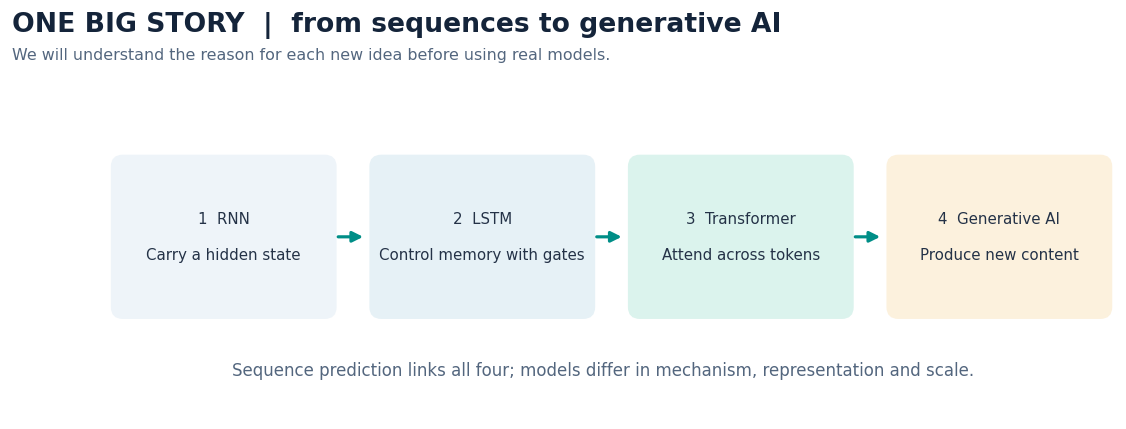

In [5]:
diagram('journey')  # This illustration is reproduced by the drawing helpers above.

---
# SECTION 1 - What did our LSTM actually do?

### 1.1 First, remember our music assignment

In the earlier lab, the model saw a sequence of music events such as `C, D, E, G` and tried to predict a sensible next event. The same type of problem appears in language:

- Music: `C → D → E → G → ?`
- Text: `The student opened the → ?`
- Sensors: `24.1°C → 24.3°C → 24.8°C → ?`

**Why is this difficult?** The next item depends on earlier items. Sometimes only the most recent few matter. In other cases something near the start matters much later.

### 1.2 Recurrent memory

An ordinary recurrent neural network (RNN) keeps a **hidden state**, often written `hₜ`. At each time step it combines the next input with information passed forward from earlier steps.

An LSTM is a more sophisticated RNN with gates that help regulate memory:

- **Forget gate:** decides how much existing cell-state information to keep.
- **Input gate:** regulates newly written information.
- **Output gate:** controls information revealed in the hidden state.

These gates are *learned numerical operations*, not human-written `if` statements or perfect memory switches. LSTMs greatly improved sequence modelling, but recurrent dependencies still make processing many time steps harder to parallelise.

### Visual 1 - Sequential memory versus attention

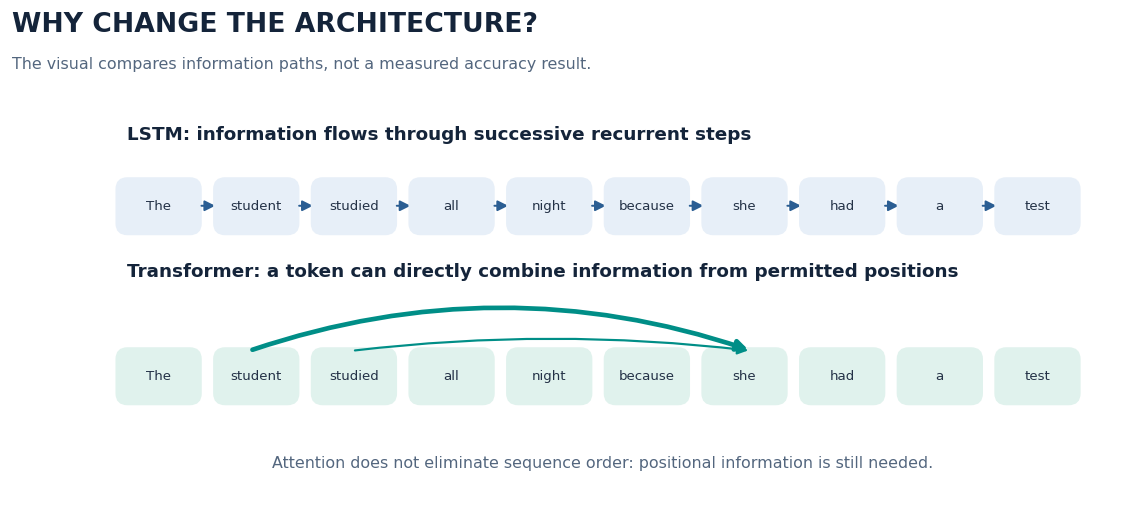

In [6]:
diagram('sequence')  # This illustration is reproduced by the drawing helpers above.

### Prediction before running code

In the sentence below, what does the word **she** most likely refer to?

> The student submitted the assignment because she finished it.

Now imagine adding 100 unrelated words between **student** and **she**. Would it necessarily be impossible for an LSTM to link them? **No.** But preserving and learning long-range dependencies is one reason alternative architectures became attractive.

### Prediction — pronoun reference

The most likely referent of **“she”** is **the student**, because the sentence says the student finished the assignment and then submitted it. This is a likely reading of the sentence, not proof that attention weights alone can identify the correct referent.

### Visual 2 - Long-distance relationships

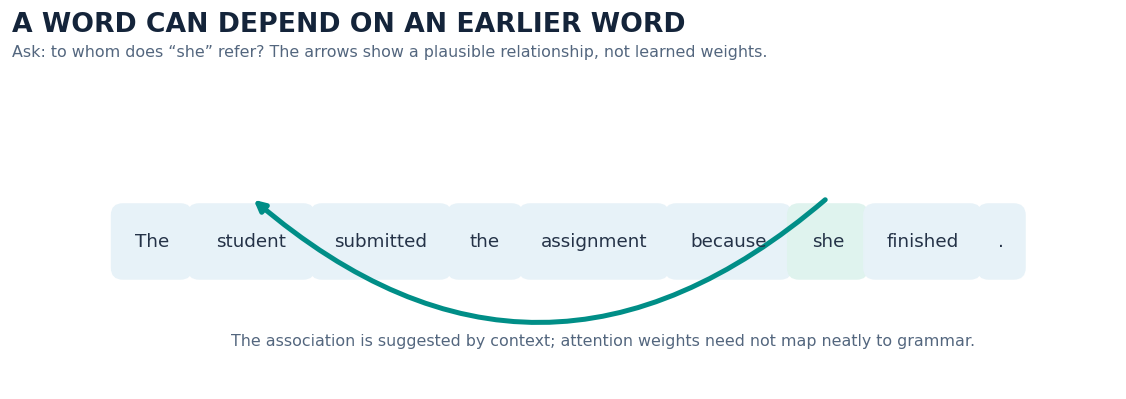

In [7]:
diagram('reference')  # This illustration is reproduced by the drawing helpers above.

**Think and explain:** A Transformer does not simply “remember better.” It changes how token representations gather contextual information. A token can directly combine information from other *permitted* positions, rather than relying exclusively on a recurrent chain. Keep in mind that the architecture itself does not guarantee correct meaning or grammar.

### 1.3 A tiny reminder of the prediction task

Before introducing a large model, let's write a very basic next-event predictor. This is a **hand-written teaching rule**, not machine learning. That contrast is deliberate: a learned model develops numerical weights from data instead of following only our predefined choices.

### Reflection — the hand-written music rule

The rule maps `G` to `A`, so for the input melody `C, D, E, G` it predicts `A`. If the music followed a different pattern, this fixed mapping could make an unsuitable prediction because it does not learn from examples or adapt to context. A trained sequence model can learn statistical patterns from data, although its predictions are still not guaranteed to be correct.

In [8]:
# A deliberately simple rule-based example: not an RNN, LSTM or Transformer.
transitions = {
    'C': 'D', 'D': 'E', 'E': 'G', 'G': 'A', 'A': 'C'
}
melody = ['C', 'D', 'E', 'G']
print('Input melody:', melody)
print('Rule-based next note:', transitions[melody[-1]])
print('Question: What would happen if the music followed a different pattern?')

Input melody: ['C', 'D', 'E', 'G']
Rule-based next note: A
Question: What would happen if the music followed a different pattern?


**Key idea:** In our next experiments, the model’s learned weights will replace this hand-written mapping. The transition from LSTM to Transformer concerns *how those learned models process sequence information*.

---
# SECTION 2 - The language of a Transformer: tokens and vectors

You cannot understand attention until you know what enters it.

### 2.1 Computers do not directly calculate with English words

A model first converts text into **tokens**, and a tokenizer maps those tokens to numeric **IDs**. A learned embedding table then maps IDs to **vectors**.

Think of an embedding as a numerical representation. It is not a dictionary definition. The model learns values that are useful for its training tasks; later layers adjust those representations according to context.

For example, the word *bank* might be used in *river bank* or *bank account*. Real Transformer representations can vary with their surrounding words.

### Visual 3 - Text → token IDs → numerical vectors

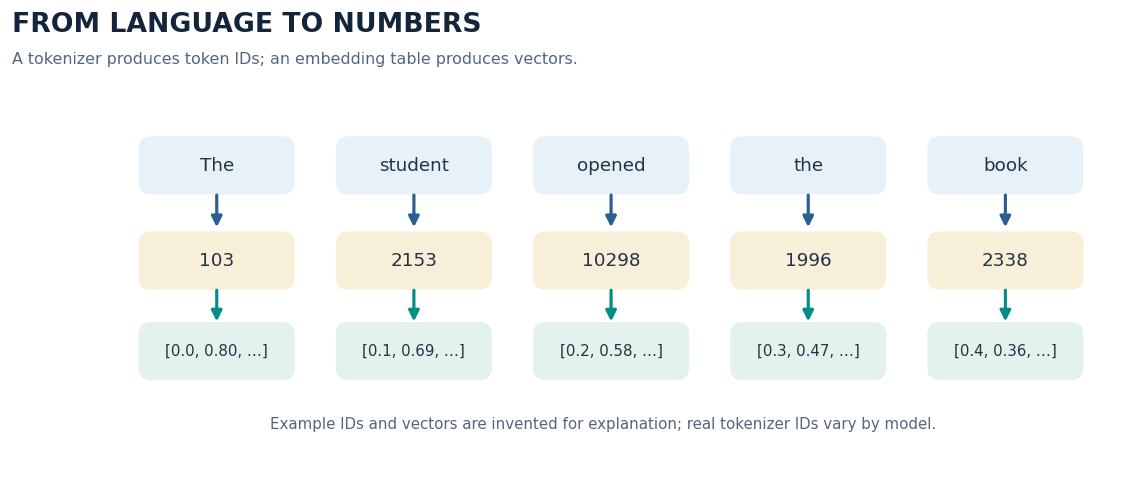

In [9]:
diagram('tokens')  # This illustration is reproduced by the drawing helpers above.

### 2.2 What is a vector?

A vector is simply an ordered list of numbers. You have already used lists in Python; arrays do a similar job while supporting mathematical operations.

For teaching, imagine:

- `student` → `[1.0, 0.2]`
- `submitted` → `[0.1, 1.0]`
- `she` → `[0.8, 0.4]`

These are **invented two-dimensional examples**, not embeddings from a trained language model. Real embeddings commonly contain hundreds or thousands of values. A vector's individual coordinates usually do not have simple human-readable labels.

### Reflection — vector shape

`X.shape` is `(3, 2)`: there are three token rows (`student`, `submitted`, `she`) and two numeric features per token. These dimensions matter because the matrix multiplications for Q, K and V require compatible shapes; the output here also has three rows, one per token.

In [10]:
# Toy word representations. We made these numbers up to study the calculations.
words = ['student', 'submitted', 'she']
X = np.array([
    [1.0, 0.2],  # student
    [0.1, 1.0],  # submitted
    [0.8, 0.4]   # she
], dtype=float)
print('Words:', words)
print('Vector array X:\n', X)
print('Shape:', X.shape, '= 3 tokens, each represented by 2 numbers')

Words: ['student', 'submitted', 'she']
Vector array X:
 [[1.  0.2]
 [0.1 1. ]
 [0.8 0.4]]
Shape: (3, 2) = 3 tokens, each represented by 2 numbers


**Stop and think:** Why do we use `X.shape`? It tells us the number of tokens and the number of numerical features per token. We will need these dimensions when multiplying matrices for attention.

### 2.3 The embeddings may change during training

A model begins with an architecture and initial numerical parameters. Training repeatedly compares outputs to training objectives and updates weights. The pretrained models later in this notebook already have trained parameters; our small arrays above do not.

---
# SECTION 3 - Understand self-attention, one calculation at a time

This is the heart of the notebook. Do not skip the explanations to get to the large model: these calculations tell you **what makes a Transformer different**.

### 3.1 The central idea

For each token, calculate how strongly it should combine information from the available tokens. A weighted combination gives a new, context-sensitive numerical representation.

We often describe the process using three vectors:

- **Query (Q):** representation used to seek relevant information.
- **Key (K):** representation used to compute a matching score with a query.
- **Value (V):** representation that contributes information to the weighted result.

These names are an analogy. Q is *not* an English question, K is *not* a dictionary key, and V is *not* a literal factual answer. They are numeric projections normally computed using learned weight matrices.

### Visual 4 - What Q, K and V do

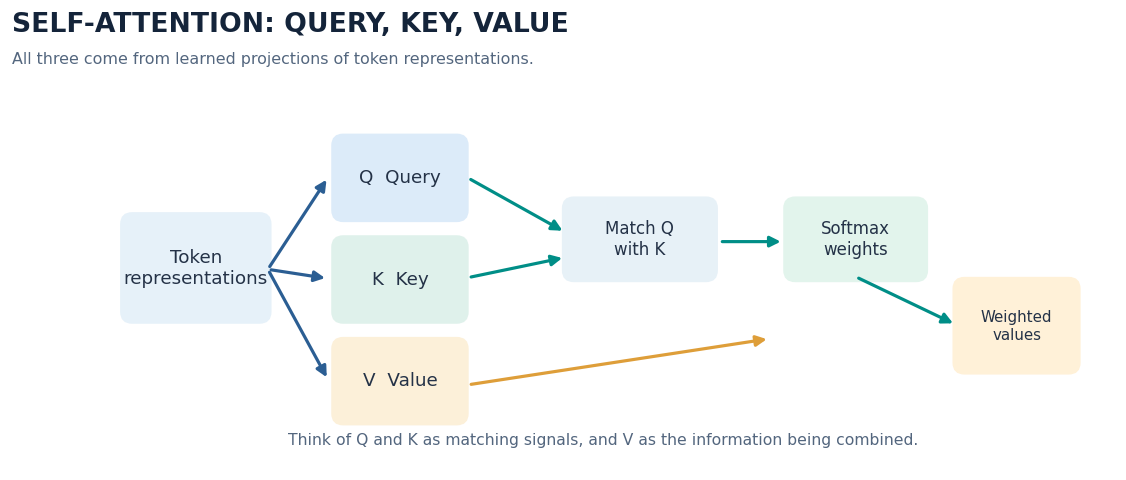

In [11]:
diagram('qkv')  # This illustration is reproduced by the drawing helpers above.

### 3.2 Step 1: create Q, K and V

A trained model uses learned matrices `W_Q`, `W_K` and `W_V` to transform each input representation:

`Q = X @ W_Q`, `K = X @ W_K`, `V = X @ W_V`.

The symbol `@` means matrix multiplication in Python. You do not need to multiply a large matrix by hand. For this example only, we choose simple projection matrices ourselves so the process is transparent; they are **not pretrained**.

### Reflection — changing a toy input

If I change one number in the `student` row of `X` and rerun the calculations from that point onward, the corresponding Query, Key and Value vectors change. That can change matching scores, attention weights and the resulting context vectors for one or more tokens. The meaning is that attention results depend on input representations; because these vectors are invented, the change demonstrates numerical sensitivity rather than a semantic improvement.

In [12]:
# STEP 1. Toy projection matrices. In a real Transformer these are learned.
W_Q = np.eye(2)  # identity: keeps the numbers unchanged, only for this example
W_K = np.eye(2)
W_V = np.array([[1.0, 0.3], [0.2, 1.0]])
Q = X @ W_Q
K = X @ W_K
V = X @ W_V
print('Queries Q:\n', Q)
print('\nKeys K:\n', K)
print('\nValues V:\n', V)
print('\nEach has the shape:', Q.shape)

Queries Q:
 [[1.  0.2]
 [0.1 1. ]
 [0.8 0.4]]

Keys K:
 [[1.  0.2]
 [0.1 1. ]
 [0.8 0.4]]

Values V:
 [[1.04 0.5 ]
 [0.3  1.03]
 [0.88 0.64]]

Each has the shape: (3, 2)


### 3.3 Step 2: calculate matching scores

We compare each Query vector with the Key vectors. A common way to calculate this match is a **dot product**. In code, `Q @ K.T` compares every query with every key. The `.T` means transpose: change rows into columns so the dimensions align.

Why divide by `sqrt(d_k)`? As vector size increases, raw dot-product magnitudes can grow. Scaling helps keep the softmax inputs numerically manageable. `d_k` is the number of elements in each Key vector.

In [13]:
# STEP 2. Scores have one row for each query and one column for each key.
d_k = K.shape[1]
scores = (Q @ K.T) / np.sqrt(d_k)
print('Number of values in each key d_k:', d_k)
print('Scaled matching scores:\n', np.round(scores, 3))
print('Shape:', scores.shape, '= 3 queries × 3 keys')

Number of values in each key d_k: 2
Scaled matching scores:
 [[0.735 0.212 0.622]
 [0.212 0.714 0.339]
 [0.622 0.339 0.566]]
Shape: (3, 3) = 3 queries × 3 keys


### 3.4 Step 3: turn matching scores into weights (softmax)

The scores can be negative or positive. They are *not yet probabilities*. A function called **softmax** turns scores into nonnegative weights that add up to 1 across each query's row.

For a given token, a weight such as `0.55` means 55% of that token's **weighted combination of Value vectors** comes from one source position in this attention head. It does *not* mean the model is 55% certain of an English sentence, and it is not automatically an explanation of a decision.

In [14]:
# STEP 3. Stable softmax: subtract each row's maximum before exponentiation.
def softmax(arr, axis=-1):
    shifted = arr - np.max(arr, axis=axis, keepdims=True)
    e = np.exp(shifted)
    return e / np.sum(e, axis=axis, keepdims=True)

weights = softmax(scores, axis=1)
print('Attention weights:\n', np.round(weights, 3))
print('Each row sums to:', weights.sum(axis=1).round(6))
assert np.allclose(weights.sum(axis=1), 1), 'Each attention row must sum to one.'

Attention weights:
 [[0.402 0.238 0.359]
 [0.264 0.436 0.3  ]
 [0.371 0.279 0.35 ]]
Each row sums to: [1. 1. 1.]


### 3.5 Step 4: combine the Values

Now use the attention weights to calculate a weighted mixture of the Value vectors. For example, if three weights are `[0.5, 0.3, 0.2]`, then the output is `0.5 × value₁ + 0.3 × value₂ + 0.2 × value₃`.

The output is another vector. It can be passed into later neural-network layers. **Attention does not directly output the next English word.** That happens after further model processing and a final prediction head.

In [15]:
# STEP 4. The output of attention is a new vector for each query token.
context_vectors = weights @ V
print('Attention output vectors:\n', context_vectors.round(3))
print('\nFull attention calculation, all four steps:')
print('softmax((Q @ K.T) / sqrt(d_k)) @ V')
assert context_vectors.shape == X.shape

Attention output vectors:
 [[0.806 0.677]
 [0.669 0.773]
 [0.777 0.697]]

Full attention calculation, all four steps:
softmax((Q @ K.T) / sqrt(d_k)) @ V


### 3.6 Our first real heatmap - these numbers came from OUR code

A **heatmap** uses colour to show numerical strength. The vertical axis identifies which token is asking for information (Query). The horizontal axis identifies the token supplying information (Key / Value). Darker colours indicate larger attention weights.

**Read one complete row**, not one column. The row sums to 1. With this tiny untrained example the values are unlikely to express sensible grammar. That is expected: the purpose is to understand the *mechanism*.

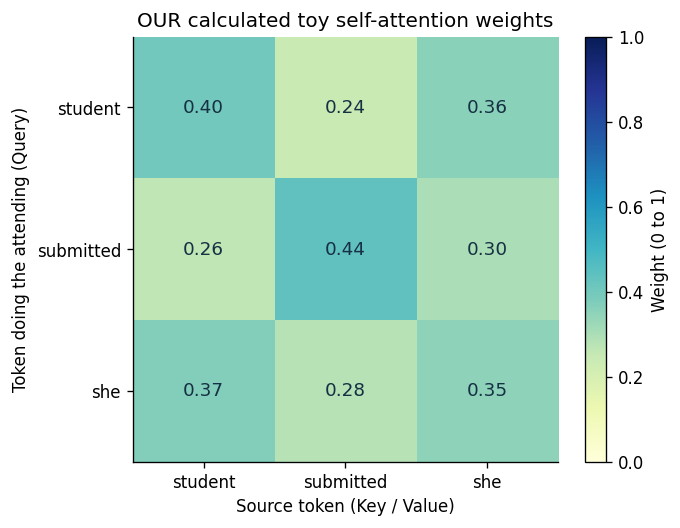

In [16]:
# Visual 5. This heatmap is generated from the attention weights calculated above.
fig, ax = plt.subplots(figsize=(7.3, 4.6))
im = ax.imshow(weights, cmap='YlGnBu', vmin=0, vmax=1)
ax.set_xticks(range(len(words)), words)
ax.set_yticks(range(len(words)), words)
ax.set_xlabel('Source token (Key / Value)')
ax.set_ylabel('Token doing the attending (Query)')
ax.set_title('OUR calculated toy self-attention weights')
for r in range(len(words)):
    for c in range(len(words)):
        ax.text(c,r,f'{weights[r,c]:.2f}',ha='center',va='center',
                color='white' if weights[r,c]>.55 else '#163044',fontsize=11)
fig.colorbar(im,ax=ax,fraction=.047,pad=.04,label='Weight (0 to 1)')
plt.show()

#### Try it yourself: edit one number, see what changes

Change the `focus` variable below to 0, 1 or 2. The code will print which source token contributes the **largest weight** for that query. Then change the `student` vector in `X` (in Section 2), rerun the cells from that point, and see whether the pattern changes. You are observing arithmetic, not semantic understanding.

In [17]:
# CHANGE ME: 0=student, 1=submitted, 2=she
focus = 2
assert 0 <= focus < len(words)
row = weights[focus]
strongest = int(np.argmax(row))
print('Query token:', words[focus])
print('Its attention weights:', dict(zip(words, row.round(3))))
print('Largest illustrative weight comes from:', words[strongest])

Query token: she
Its attention weights: {'student': np.float64(0.371), 'submitted': np.float64(0.279), 'she': np.float64(0.35)}
Largest illustrative weight comes from: student


### Reflection — interpreting the attention experiment

I changed `focus` to `2`, which selects **she** as the query token. The row contains weights for `student`, `submitted` and `she`; with the notebook's toy inputs they are approximately **0.371, 0.279 and 0.350**. The largest weight is on `student`, but the difference is modest. This shows how the chosen numbers distribute attention over the available Value vectors; it does **not** prove that “student” is the true antecedent of “she.” The projections are deliberately simple and are not trained language-model weights.

### 3.7 What is the famous attention equation saying?

$$
\operatorname{Attention}(Q,K,V)=\operatorname{softmax}\!\left(\frac{QK^{T}}{\sqrt{d_k}}\right)V
$$

You have **already implemented it**. In plain English:

1. Compare each Query with all Keys.
2. Scale the matching scores.
3. Convert scores to relative weights using softmax.
4. Use those weights to blend Value vectors.

**Predict → run → explain:** If one query assigns 70% weight to one source token, does that prove that token is “the true meaning” of the sentence? **No.** It means that attention head placed relatively more weight on that Value vector in that context. Model behaviour also depends on other heads, later layers and trained parameters.

---
# SECTION 4 - What else does a Transformer need?

Self-attention is central, but it is not an entire Transformer. We now add the pieces introduced in Tutorial 17: **position**, **multiple heads**, **masking** and **blocks**.

### 4.1 Order still matters

Compare:

- `Dog bites man.`
- `Man bites dog.`

These sentences contain almost the same token set but have different meanings. Self-attention without any positional information treats the inputs as a set, up to corresponding permutation of the outputs. A Transformer needs information about *where* items occur.

Architectures can use learned positions, sinusoidal encodings, rotary embeddings and other methods. The graph below illustrates a classic **sinusoidal pattern**, not the exact positional scheme used by every contemporary model.

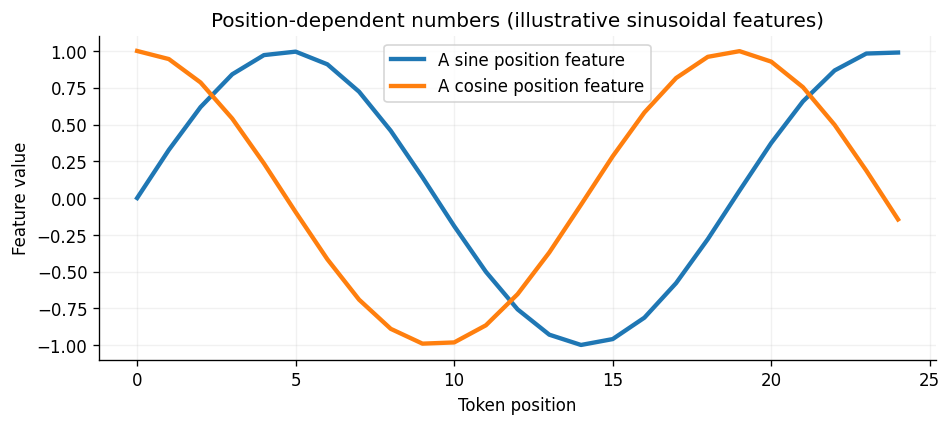

In [18]:
# Visual 6. A simple example of position-dependent sine/cosine signals.
positions = np.arange(0, 25)
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(positions, np.sin(positions/3),label='A sine position feature',lw=2.6)
ax.plot(positions, np.cos(positions/3),label='A cosine position feature',lw=2.6)
ax.set_title('Position-dependent numbers (illustrative sinusoidal features)')
ax.set_xlabel('Token position'); ax.set_ylabel('Feature value')
ax.grid(alpha=.17);ax.legend()
plt.show()

**Interpretation:** The position signals change as token position changes, so the model receives information that distinguishes an arrangement such as `dog / bites / man` from `man / bites / dog`. One sine wave is only an illustration; real positional systems use richer mechanisms.

### 4.2 Multi-head attention

So far we built *one* attention head. A Transformer often has multiple heads. Each head has separate projection matrices and can learn different patterns of information exchange.

Do not assume head 1 is “grammar,” head 2 is “meaning” and head 3 is “logic.” Actual heads may overlap, mix roles and vary across examples.

### Visual 7 - Multiple heads can produce different weight patterns

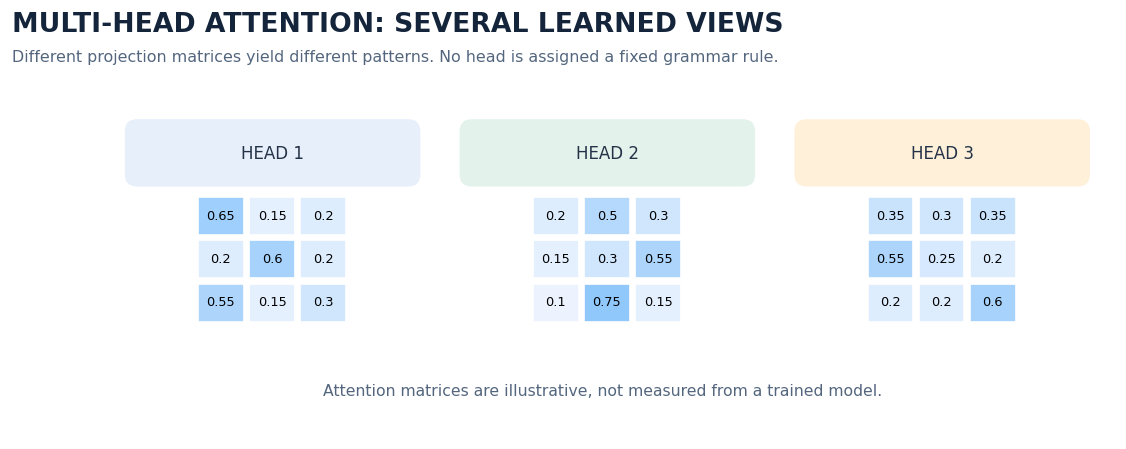

In [19]:
diagram('multihead')  # This illustration is reproduced by the drawing helpers above.

### 4.3 Causal masking - a very important idea

Imagine you are training a model to predict the next word in a sentence. If it can directly look at *later* words, the training objective becomes misleading: it has accessed the future answers.

A **causal mask** allows a token at position `i` to attend only to itself and earlier positions. It hides future positions by setting their attention scores to an extremely negative value before softmax.

This is especially important for **decoder-only autoregressive models**. A bidirectional encoder used for reading tasks generally follows different visibility rules.

### Visual 8 - A lower-triangular causal mask

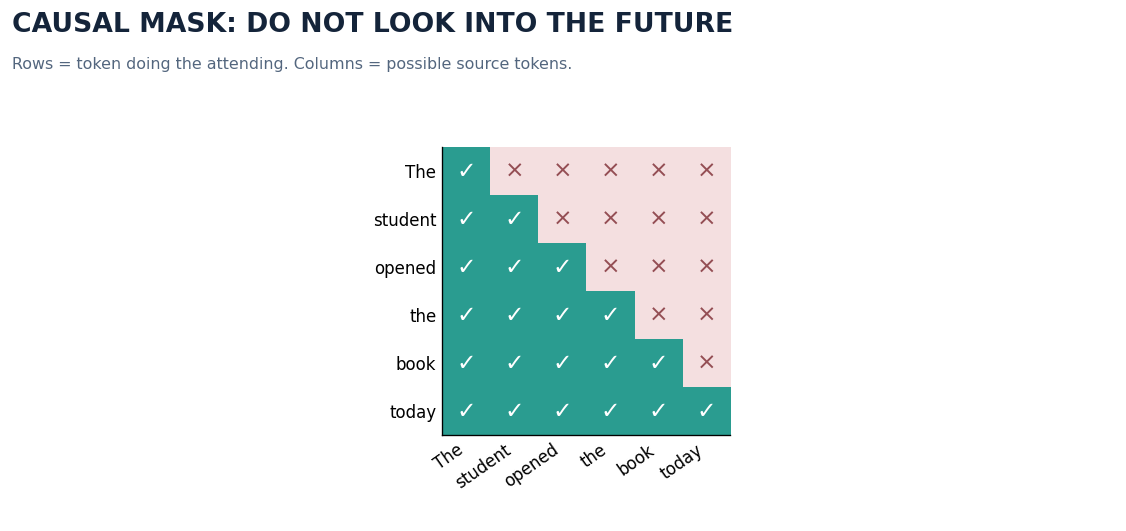

In [20]:
diagram('mask')  # This illustration is reproduced by the drawing helpers above.

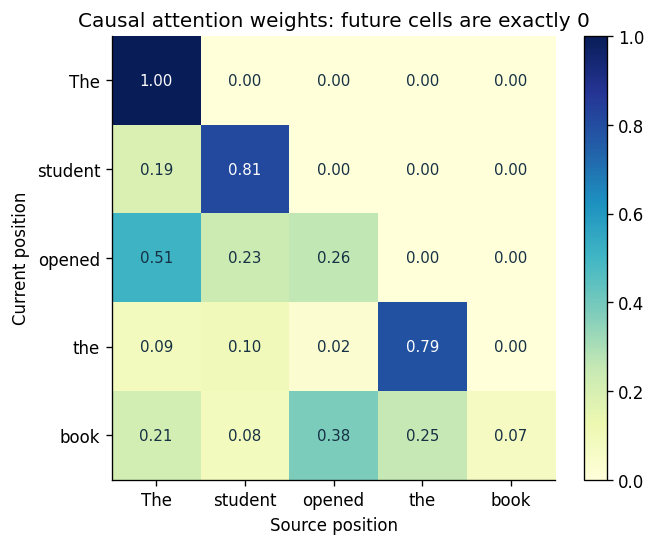

In [21]:
# Visual 9. We mask future positions and show the resulting attention weights.
toy_tokens = ['The', 'student', 'opened', 'the', 'book']
n = len(toy_tokens)
rng = np.random.default_rng(13)
raw_scores = rng.normal(size=(n, n))
allowed = np.tril(np.ones((n, n), dtype=bool))
masked_scores = np.where(allowed, raw_scores, -1e9)
causal_weights = softmax(masked_scores, axis=1)
fig, ax = plt.subplots(figsize=(7.8,4.8))
im = ax.imshow(causal_weights,cmap='YlGnBu',vmin=0,vmax=1)
ax.set_xticks(range(n),toy_tokens);ax.set_yticks(range(n),toy_tokens)
ax.set_xlabel('Source position');ax.set_ylabel('Current position')
ax.set_title('Causal attention weights: future cells are exactly 0')
for r in range(n):
    for c in range(n):
        ax.text(c,r,f'{causal_weights[r,c]:.2f}',ha='center',va='center',
                color='white' if causal_weights[r,c]>.6 else '#163044',fontsize=9)
fig.colorbar(im,ax=ax,fraction=.046,pad=.04)
plt.show()
assert np.allclose(causal_weights[~allowed],0)

### Reflection — interpreting the causal mask

The mask keeps the diagonal and lower triangle available, while future-token positions in the upper-right are assigned a very negative score before softmax and therefore receive **zero attention weight**. For the five-token sequence, row 4 can use positions 1–4 but not position 5. Later rows have more context because more earlier positions are available. The scores are random teaching values, so this demonstrates the visibility rule rather than learned language behaviour.

**Explain in one sentence:** Why do the upper-right cells have zero weight? Why do later rows have more available context? Notice that these are random example scores, **not weights from a pretrained Transformer**.

### 4.4 A full Transformer block

After attention, a Transformer block also transforms the resulting vectors through a feed-forward network. Residual connections and normalisation help deep architectures train effectively. Many layers can be stacked.

There are three broad model families:

1. **Encoder-only:** usually useful for reading, classifying or extracting information from input.
2. **Decoder-only:** often used to predict successive tokens and generate text or code.
3. **Encoder–decoder:** reads an input sequence and generates a related output (e.g. translation or summarisation).

These are common uses, not absolute restrictions. We will use an encoder-style model for extraction and an instruction-tuned generative model for producing new content.

### Visual 10 - The simplified processing block

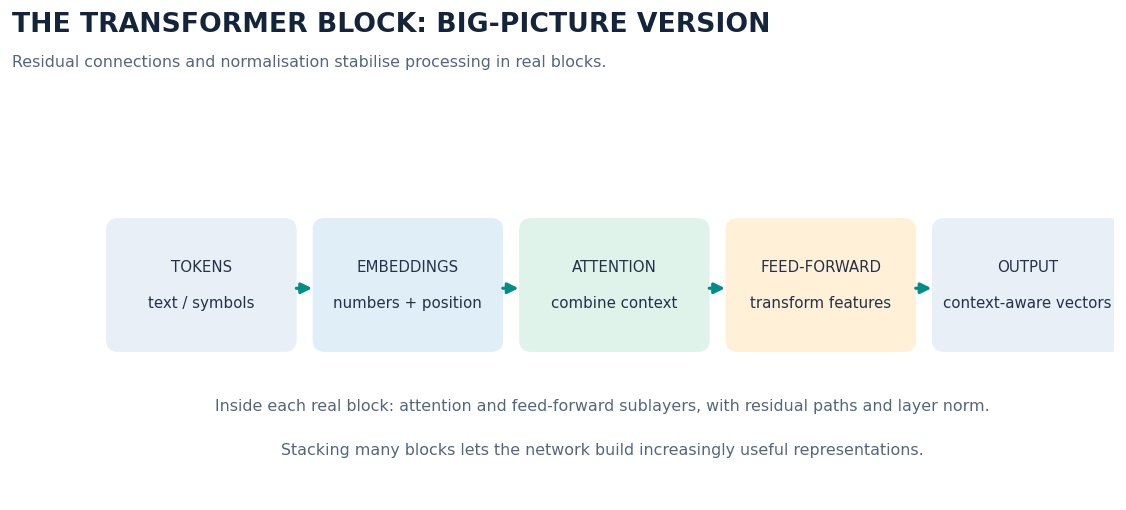

In [22]:
diagram('architecture')  # This illustration is reproduced by the drawing helpers above.

### Visual 11 - Which Transformer does which kind of work?

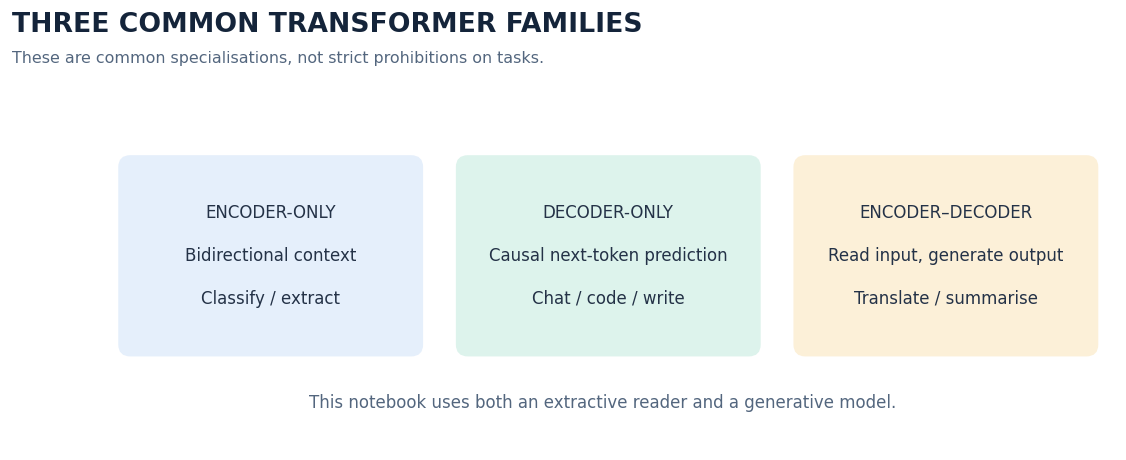

In [23]:
diagram('family')  # This illustration is reproduced by the drawing helpers above.

### 4.5 So why aren't Transformers used for everything?

Standard dense self-attention compares many pairs of tokens, which can have substantial computational and memory costs at long sequence lengths. A basic attention score matrix contains `n × n` entries for `n` tokens. More efficient attention techniques exist, and real-world costs also depend on hardware and implementation.

LSTMs and other compact sequence models can remain attractive for **streaming sensors, limited devices and smaller problems**. A good engineer makes decisions from requirements, not popularity.

### Visual 12 - Why long contexts can be expensive

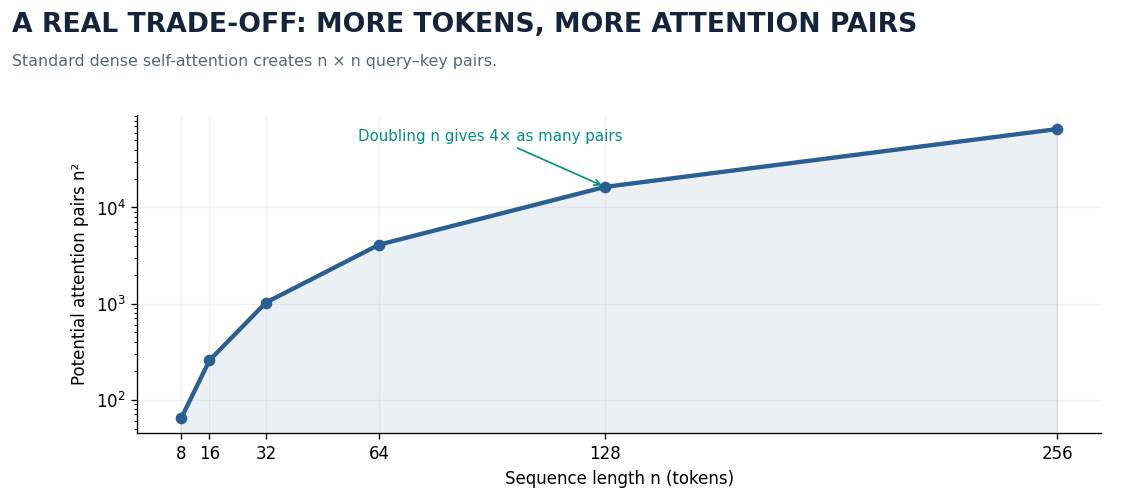

In [24]:
diagram('cost')  # This illustration is reproduced by the drawing helpers above.

In [25]:
# How many query-key pair scores are in a standard dense attention matrix?
for n in [10, 20, 50, 100]:
    print(f'{n:>3} tokens -> {n*n:>6} pair scores per attention head')

 10 tokens ->    100 pair scores per attention head
 20 tokens ->    400 pair scores per attention head
 50 tokens ->   2500 pair scores per attention head
100 tokens ->  10000 pair scores per attention head


### Reflection — attention cost

The loop prints 100, 400, 2,500 and 10,000 query–key pair scores for sequence lengths 10, 20, 50 and 100. Doubling the number of tokens quadruples the number of pair scores because the count is \(n^2\). This quadratic growth helps explain why standard dense self-attention can become expensive for long contexts, although efficient attention methods and hardware can change the practical cost.

---
# SECTION 5 - WOW EXPERIMENT ONE: a real Transformer that reads

**Everything so far was a numerical teaching demonstration. We now run a real pretrained language model.**

### 5.1 What task are we solving?

We give a model a **passage** and a **question**, and it predicts an answer span from that passage. This is called *extractive question answering*. You do not have to write a program that manually searches each sentence.

The model we'll use is a distilled, encoder-based Transformer fine-tuned to locate answers in English passages.

**Why use a pretrained model?** Training a strong language model from scratch requires data and compute well beyond this class. We can focus on *inference* (using existing learned weights) and analyse its behaviour.

### Visual 13 - A reader identifies an answer span

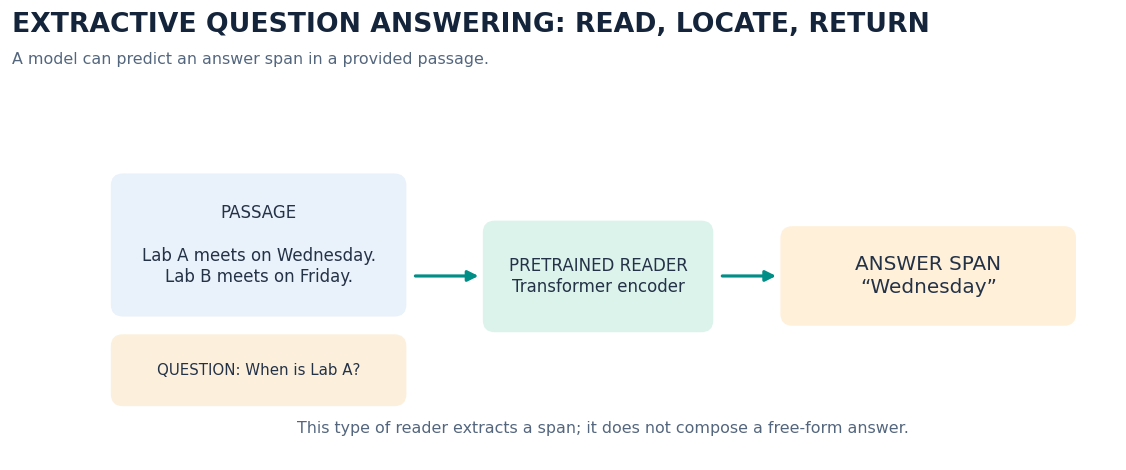

In [26]:
diagram('qa')  # This illustration is reproduced by the drawing helpers above.

### 5.2 A fictional campus notice

Read the following passage before the model does. The dates and events are **invented for this exercise**, not actual UCU policy.

> The Department of Computing is organising an Artificial Intelligence practical workshop. The workshop is scheduled for Wednesday, 18 November, in Laboratory B. Registration closes on Monday, 16 November. Students must bring a laptop and their university identification card. The workshop coordinator is Dr. Amina Nsubuga.

**Predict first:** Without running Python, answer: *Where will the workshop take place?* Then compare your answer with the model's output.

In [27]:
# Download and load a small REAL pretrained extractive-question-answering Transformer.
# First execution requires an internet connection.
from transformers import pipeline, AutoTokenizer
QA_MODEL_ID = 'distilbert/distilbert-base-cased-distilled-squad'
qa = pipeline('question-answering', model=QA_MODEL_ID, tokenizer=QA_MODEL_ID,
              device=0 if torch.cuda.is_available() else -1)
print('Loaded:', QA_MODEL_ID)
print('This model returns a span from the supplied context, not a newly composed essay.')

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/473 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/261M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Device set to use cuda:0


Loaded: distilbert/distilbert-base-cased-distilled-squad
This model returns a span from the supplied context, not a newly composed essay.


In [28]:
context = (
    'The Department of Computing is organising an Artificial Intelligence practical '
    'workshop. The workshop is scheduled for Wednesday, 18 November, in Laboratory B. '
    'Registration closes on Monday, 16 November. Students must bring a laptop and '
    'their university identification card. The workshop coordinator is Dr. Amina Nsubuga.'
)
question = 'Where will the workshop take place?'  # CHANGE ME
result = qa(question=question, context=context)
print('Question:', question)
print('Model-extracted answer:', result['answer'])
print('Model span score:', round(result['score'], 3))
print('Is it supported by the passage?', result['answer'].strip().lower() in context.lower())

Question: Where will the workshop take place?
Model-extracted answer: Laboratory B
Model span score: 0.672
Is it supported by the passage? True


### Reflection — extractive reading

The passage itself states that the workshop is in **Laboratory B**, so that is the evidence-based answer to the first question. The model is being asked to select a span from supplied text, not independently verify university information. Record the actual answer and score produced by your run, then check that the returned span occurs in the passage; the score is not a truth probability.

**Critical interpretation:** A high `score` is a score for the model's selected span. It is **not** a calibrated probability that the real-world statement is true. The model can only extract from text it receives, and that text can itself contain errors.

### 5.3 Show the answer in its original passage

We will highlight the returned span instead of merely printing text. That helps us judge whether the model selected the right evidence.

In [29]:
# Visual 14. Highlight the EXACT span from the model result, if it exists in the context.
from html import escape
start = result['start']; end = result['end']
if 0 <= start < end <= len(context):
    highlighted = (escape(context[:start]) +
                   '<mark style="background:#bdebdc;padding:2px 4px">' +
                   escape(context[start:end]) + '</mark>' +
                   escape(context[end:]))
    display(HTML('<div style="font:17px/1.8 Arial;padding:18px;'
                 'border:1px solid #d3dfea;border-radius:10px">'+highlighted+'</div>'))
else:
    print('The model output has no valid extractive character span.')

### 5.4 Now investigate rather than admire

Change the question several times:

- Who coordinates the workshop?
- When does registration close?
- What must participants bring?
- What is the university's annual budget?

**The last question matters.** The passage does not contain the annual budget. This particular model was trained for a task in which answers are normally present, so it may still select an irrelevant span. You must not treat a forced answer as verified information.

In [30]:
questions = [
    'Who is the workshop coordinator?',
    'When does registration close?',
    'What must students bring?',
    "What is the university's annual budget?"  # No answer in the passage!
]
for q in questions:
    r = qa(question=q, context=context)
    print(f'Q: {q}\nModel span: {r["answer"]!r} | span score: {r["score"]:.3f}\n')

Q: Who is the workshop coordinator?
Model span: 'Dr. Amina Nsubuga' | span score: 0.901

Q: When does registration close?
Model span: 'Monday, 16 November' | span score: 0.931

Q: What must students bring?
Model span: 'a laptop and their university identification card' | span score: 0.311

Q: What is the university's annual budget?
Model span: 'Students must bring a laptop and their university identification card' | span score: 0.240



### Reflection — answerable versus unanswerable questions

The coordinator, registration deadline and required items are explicitly stated in the fictional passage, so answers matching those facts are grounded. The annual budget is absent, so any span returned for that question is unsupported even if it sounds confident. A careful application should detect insufficient evidence, abstain or ask for an authorised source rather than present a forced span as fact. The model's actual outputs can vary; compare them with the passage after running the cell.

**Explain:** Which answers were grounded in the passage? Which question lacked enough information? Even if the model returned fluent text, what should a careful application do when the evidence is absent?

### 5.5 Tokenization is real, not one word = one token

Let's inspect what the pretrained model actually sees. Most Transformer tokenizers use **subword tokens**, so unusual names or terms might split into several pieces. Special tokens such as `[CLS]` or `[SEP]` may also be inserted.

In [31]:
reader_tokenizer = AutoTokenizer.from_pretrained(QA_MODEL_ID)
sentence = 'Transformers can analyse unfamiliar terminology.'
encoded = reader_tokenizer(sentence, add_special_tokens=True)
tokens = reader_tokenizer.convert_ids_to_tokens(encoded['input_ids'])
print('Original text:', sentence)
print('Actual model tokens:', tokens)
print('Token IDs:', encoded['input_ids'])
print('Number of tokens:', len(tokens))

Original text: Transformers can analyse unfamiliar terminology.
Actual model tokens: ['[CLS]', 'Transformers', 'can', 'anal', '##ys', '##e', 'unfamiliar', 'terminology', '.', '[SEP]']
Token IDs: [101, 25267, 1169, 24443, 6834, 1162, 17546, 20925, 119, 102]
Number of tokens: 10


### Reflection — tokenization

The tokenizer converts the sentence into token IDs, often using subword pieces rather than assigning exactly one token to every English word. Special tokens may also be added. This means the model processes a numerical token sequence, not raw text directly; token boundaries depend on the tokenizer's vocabulary and rules. Use the actual printed tokens and IDs from your run as evidence, especially for any word split into pieces.

---
# SECTION 6 - WOW EXPERIMENT TWO: a Transformer that writes

The reader **selects words already present** in a passage. A generative language model can **produce a new sequence**.

A decoder-only autoregressive model predicts the next token, appends it to the context, and repeats. A token may represent a word or part of a word. During generation the outputs are produced successively; during training, causal masking allows many next-token positions to be evaluated in parallel.

Generative text is a form of **generative AI**; not every generative AI system is a language-model Transformer. Images and audio may also be generated with other architectures, including diffusion models.

### Visual 15 - The generation loop

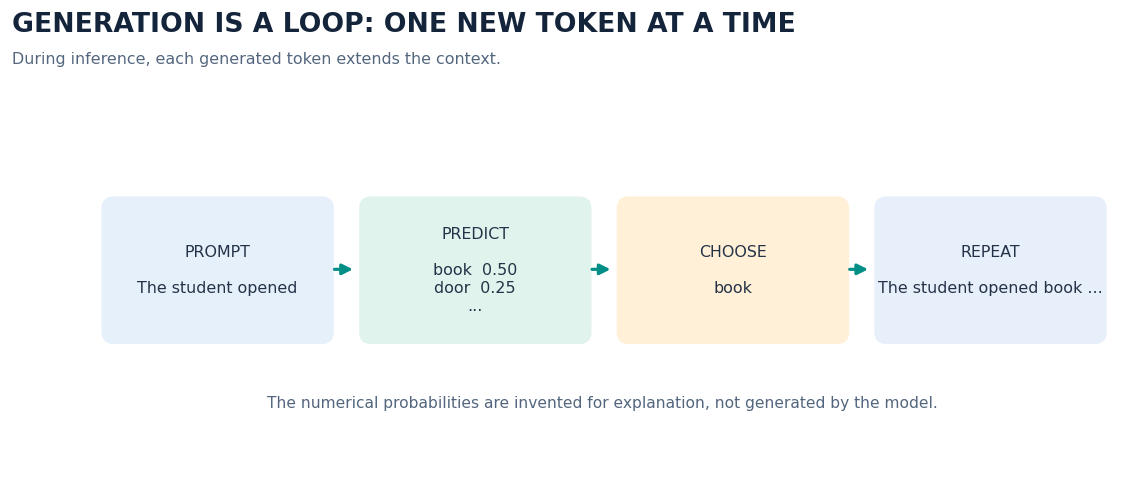

In [32]:
diagram('generation')  # This illustration is reproduced by the drawing helpers above.

### 6.1 Which model will we use?

- **If Colab has a GPU:** use **Qwen2.5-0.5B-Instruct**, an instruction-tuned, decoder-only language model. It can generate text and basic code, but it is *small*, and should not be judged against much larger production models.
- **If Colab has CPU only:** use **FLAN-T5 Small**, a more compact encoder–decoder model that can follow simple text instructions. Outputs may be shorter and less reliable. It is a fallback, not exactly the same architecture.

In both cases, the weights were learned **before** this lab. We are not training the model, and ordinary prompting does not modify its weights.

**Memory note:** These small models can still take time to download and generate. Avoid very long prompts and lengthy outputs. A runtime restart may require reloading the model.

In [33]:
# Load ONE instruction-following model based on available hardware.
# Model checkpoint downloads require internet access.
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoModelForSeq2SeqLM

USE_QWEN = torch.cuda.is_available()
if USE_QWEN:
    GEN_ID = 'Qwen/Qwen2.5-0.5B-Instruct'
    gen_tokenizer = AutoTokenizer.from_pretrained(GEN_ID)
    gen_model = AutoModelForCausalLM.from_pretrained(GEN_ID, torch_dtype=torch.float16)
    gen_model = gen_model.to('cuda').eval()
    GEN_KIND = 'decoder-only'
else:
    GEN_ID = 'google/flan-t5-small'
    gen_tokenizer = AutoTokenizer.from_pretrained(GEN_ID)
    gen_model = AutoModelForSeq2SeqLM.from_pretrained(GEN_ID)
    gen_model = gen_model.to('cpu').eval()
    GEN_KIND = 'encoder-decoder'

print('Loaded pretrained model:', GEN_ID)
print('Model family:', GEN_KIND)
print('Device:', next(gen_model.parameters()).device)

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Loaded pretrained model: Qwen/Qwen2.5-0.5B-Instruct
Model family: decoder-only
Device: cuda:0


### 6.2 Your reusable generation function

The following function carries out three operations: **tokenize** your prompt, **generate** a sequence, and **decode** the token IDs back to readable text. For Qwen, a *chat template* formats the messages in the style expected during instruction-tuned use.

Parameters:

- `max_new_tokens`: maximum number of tokens the model adds.
- `temperature`: controls how concentrated or dispersed the next-token sampling probabilities become. It only matters when sampling is enabled.
- `sample=False`: choose the highest-scoring next token (greedy decoding); `sample=True`: sample from a probability distribution.

**Small temperatures do not guarantee facts; large temperatures do not guarantee creativity.** Both affect output selection, not the model's learned knowledge.

In [34]:
@torch.inference_mode()
def generate_answer(prompt, max_new_tokens=110, temperature=0.8, sample=False):
    max_new_tokens = min(int(max_new_tokens), 180)  # classroom-friendly limit
    if USE_QWEN:
        ids = gen_tokenizer.apply_chat_template(
            [{'role':'user','content':prompt}],
            tokenize=True, add_generation_prompt=True, return_tensors='pt'
        ).to('cuda')
        inputs = {'input_ids': ids}
    else:
        inputs = gen_tokenizer(prompt, return_tensors='pt', truncation=True,
                               max_length=480).to('cpu')
    generation_options = {
        'max_new_tokens': max_new_tokens,
        'do_sample': bool(sample),
    }
    if sample:
        generation_options.update(temperature=max(0.1,float(temperature)),top_p=0.9)
    if gen_tokenizer.pad_token_id is not None:
        generation_options['pad_token_id'] = gen_tokenizer.pad_token_id
    elif gen_tokenizer.eos_token_id is not None:
        generation_options['pad_token_id'] = gen_tokenizer.eos_token_id
    generated = gen_model.generate(**inputs, **generation_options)
    if USE_QWEN:  # Do not print the original prompt as if it was a model answer.
        continuation_ids = generated[0, inputs['input_ids'].shape[1]:]
        return gen_tokenizer.decode(continuation_ids,skip_special_tokens=True).strip()
    return gen_tokenizer.decode(generated[0],skip_special_tokens=True).strip()

print('Generation function ready. It uses the pretrained weights; no training occurs.')

Generation function ready. It uses the pretrained weights; no training occurs.


### 6.3 First experience: explain a topic

Ask the model to explain **overfitting** to a Year 2 student. Before running, predict which ideas a good answer should include. Would you accept the answer without checking the definition and example?

In [35]:
# Experiment: try a focused prompt. Students may change the prompt below.
prompt = 'Explain overfitting to a Year 2 computer science student in 3 short sentences. Give one example.'
response = generate_answer(prompt, max_new_tokens=115)
print('PROMPT:\n', prompt, '\n\nMODEL OUTPUT:\n', response)

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.


PROMPT:
 Explain overfitting to a Year 2 computer science student in 3 short sentences. Give one example. 

MODEL OUTPUT:
 Overfitting occurs when a model is too complex and captures the noise and details of the training data, rather than the underlying patterns and relationships within the dataset. This results in poor generalization ability, meaning that the model performs well on the training data but poorly on new, unseen data.

An example of overfitting would be a neural network trained on a small dataset with many features, which learns to fit the training data perfectly but fails to generalize well to new, unseen data. The model becomes overly specialized to the training set and doesn't perform as well as it could


### Reflection — evaluating the overfitting explanation

The prompt specifies the audience, length and a request for an example, which gives clear criteria for checking the response. A good answer should explain that a model can fit training examples too closely and then generalise poorly to new data. After running the cell, compare the generated explanation against that definition and verify whether its example illustrates the difference between training and unseen data. The model's wording alone is not evidence of correctness.

**Interrogate the result:** Does it explain overfitting as poor generalisation after overly fitting training data? Does the example make sense? Is anything missing or misleading? A model can provide a plausible explanation that still requires evaluation.

### 6.4 Prompt wording changes what the model tries to produce

Compare a broad instruction with an audience-specific one. The model's weights do not change between prompts; only the input changes.

In [36]:
# Keep the topic constant; compare two input instructions.
prompts = [
    'Explain neural networks.',
    'In four short sentences, explain a neural network to a Ugandan Year 2 CS student. Use a campus example.'
]
for i, p in enumerate(prompts,1):
    print(f'\n--- PROMPT {i} ---\n{p}')
    print('MODEL OUTPUT:\n', generate_answer(p,max_new_tokens=120))


--- PROMPT 1 ---
Explain neural networks.
MODEL OUTPUT:
 Neural networks are a type of machine learning model that is inspired by the structure and function of the human brain. They consist of multiple layers of interconnected nodes or "neurons," each with its own set of weights and biases.

The basic idea behind neural networks is to learn from data and make predictions based on patterns in the input data. The network consists of an input layer, one or more hidden layers, and an output layer. Each neuron in the network has a weight associated with it, which determines how much influence it will have on the output of the network when it receives an input.

During

--- PROMPT 2 ---
In four short sentences, explain a neural network to a Ugandan Year 2 CS student. Use a campus example.
MODEL OUTPUT:
 A neural network is like a smart computer that can learn from data and make predictions or decisions based on patterns it sees in the information we give it. Imagine you have a big box of cr

### Reflection — prompt comparison

The topic stays the same while the instruction changes from a broad request to a four-sentence explanation for a Ugandan Year 2 student with a campus example. This isolates prompt wording as the main changed input; the pretrained model weights remain unchanged. After running the cell, note whether the second answer follows the requested length and audience better, and whether its campus example is accurate. A more specific prompt can improve relevance but cannot guarantee truth.

**Note:** A more detailed prompt can guide style, audience and constraints. It does not automatically make the output truthful, nor does it change model parameters. Small models may ignore or only partly follow instructions.

### 6.5 Generate some code - then TEST it

We cannot judge generated programming code by appearance. The model will try to produce a Python function. Your job as an engineer is to inspect the code, check whether it handles edge cases, and run tests **only after reviewing it**. Do not automatically execute arbitrary code generated by a model.

In [37]:
code_prompt = (
    'Write a short Python function average_mark(marks) that accepts a nonempty list '
    'of numeric marks and returns the arithmetic mean. Output only Python code.'
)
print('MODEL-GENERATED CODE (inspect before running):\n')
print(generate_answer(code_prompt, max_new_tokens=150))

MODEL-GENERATED CODE (inspect before running):

```python
def average_mark(marks):
    """
    Calculate the average of a list of marks.

    Parameters:
    marks (list): A list of numeric marks.

    Returns:
    float: The average of the marks.
    """
    if not marks:
        return 0.0

    total = sum(marks)
    count = len(marks)

    return total / count

# Example usage:
marks_list = [85, 92, 76, 88]
average = average_mark(marks_list)
print(f"The average mark is: {average}")
```

This Python function `average_mark` takes a list of marks as input and calculates their average using the formula for the arithmetic mean.


### Reflection — code generation

The model-generated function must be inspected for valid syntax, correct arithmetic and edge-case behaviour before execution. The expected checks are `average_mark([50, 70, 90]) == 70` and `average_mark([100]) == 100`; an empty list needs an explicit policy because dividing by zero items is undefined. The final practical below records the model's proposed code but does not execute it automatically; it tests a separately reviewed implementation to demonstrate safe verification.

**Manual testing task:** Review the output for syntax and correctness. If it looks safe, copy the function into the next empty code cell you create and try these tests: `average_mark([50,70,90])` should return `70`; `average_mark([100])` should return `100`. Consider what your program should do for an empty list.

A convincing-looking answer is **not** evidence of a correct program. This exercise should demonstrate the need for software verification even when generative AI saves time.

---
# SECTION 7 - Control, test and question generation

### 7.1 The model predicts a distribution, not a single inevitable word

Imagine a next-token probability distribution for `The student opened the …`.

The toy numbers below are **invented**, not probabilities measured from Qwen or FLAN-T5. They help us understand temperature and sampling without loading model internals.

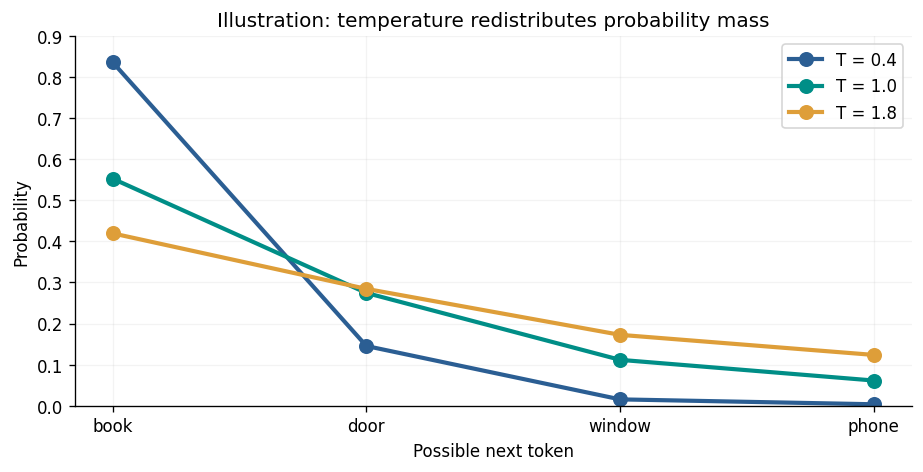

In [38]:
# Visual 16. How different temperatures change a hypothetical next-token distribution.
token_names = ['book', 'door', 'window', 'phone']
logits = np.array([2.4,1.7,0.8,0.2])  # invented unnormalised scores
fig, ax = plt.subplots(figsize=(9,4))
for temp,color in [(0.4,'#2b5e93'),(1.0,'#008e87'),(1.8,'#de9e39')]:
    probs = softmax(logits / temp)
    ax.plot(token_names,probs,marker='o',markersize=8,label=f'T = {temp}',lw=2.5,color=color)
ax.set_title('Illustration: temperature redistributes probability mass')
ax.set_xlabel('Possible next token');ax.set_ylabel('Probability')
ax.set_ylim(0,.9);ax.grid(alpha=.15);ax.legend()
plt.show()

At a lower positive temperature, the distribution concentrates more strongly on the most likely tokens. At a higher temperature it becomes flatter. **Greedy decoding** (`sample=False`) simply picks the highest-scoring token; changing temperature with sampling off does not produce meaningful diversity.

### 7.2 Experiment with sampling using the pretrained model

Keep the prompt unchanged, and run two or three times. With `sample=True`, output can vary. If running on CPU, lower `max_new_tokens` when necessary.

In [39]:
# CHANGE ME: change the temperature while keeping the prompt constant.
creative_prompt = 'Write a short, friendly opening sentence for an AI student workshop.'
torch.manual_seed(17)
print('Lower temperature:\n',generate_answer(creative_prompt,80,temperature=0.35,sample=True))
torch.manual_seed(29)
print('\nHigher temperature:\n',generate_answer(creative_prompt,80,temperature=1.2,sample=True))

Lower temperature:
 Welcome to our AI Student Workshop! We're excited to have you join us as we dive into the world of artificial intelligence and explore its fascinating applications in various fields. Whether you're curious about how AI can revolutionize your career or simply want to learn more about this cutting-edge technology, we've got something for everyone. So, let's embark on this exciting journey together and see where it takes us

Higher temperature:
 Welcome to our upcoming AI Student Workshop! Here at Alibaba Cloud, we pride ourselves on providing comprehensive knowledge and advanced skills in the fields of AI technology. Whether you're new to this exciting field or just want to deepen your understanding of its applications, this workshop is perfect for you. Don't miss out – join us and unlock your potential with cutting-edge AI knowledge and practical experience!


### Reflection — temperature experiment

The prompt remains constant while the sampling temperature and random seed change. A higher temperature generally makes the sampling distribution flatter, allowing less likely next tokens to be selected more often; this can make a response more surprising. It does not add training data or new knowledge, and a surprising response is not automatically more accurate. Compare the actual outputs and judge them for relevance, clarity and factual support rather than novelty alone.

**Explain:** Are the responses different? Is one automatically more correct? Do two sampled outputs guarantee variation? (No: random sampling can sometimes select the same tokens.)

### 7.3 Can the model be confidently wrong?

We saw this already with the extractive reader. A generative model may create fluent claims that lack evidence, including fabricated citations. The model's ability to produce a grammatical paragraph should not be confused with proof that the paragraph is true.

### Visual 17 - A reliable workflow checks evidence

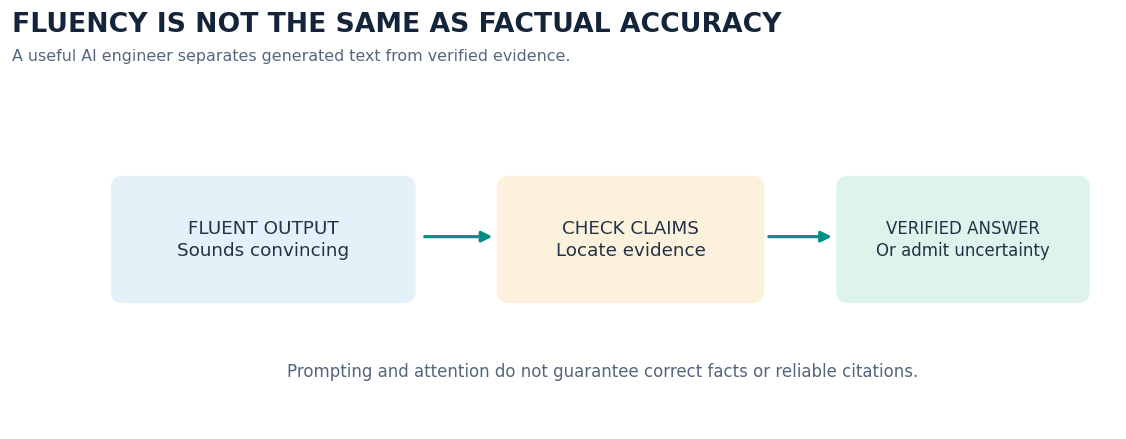

In [40]:
diagram('risk')  # This illustration is reproduced by the drawing helpers above.

### 7.4 A small evidence-grounding activity

Supply a **fictional notice** directly in the prompt. Tell the model to answer only using the notice and to say when information is missing. Test one answerable and one unanswerable question. Then independently compare each reply against the notice.

This illustrates *grounding in supplied context*, but it is **not** a full retrieval-augmented generation (RAG) system. RAG would first retrieve external information before providing it to the model.

In [41]:
notice = ('Fictional course notice: The AI revision session is on Thursday in Room 204. '
          'Students should bring a laptop. Attendance is optional.')
qs = ['Where is the revision session?', 'Who is the session speaker?']
for question in qs:
    p = ('Use ONLY this notice to answer. If the notice does not contain the answer, '
         'reply exactly: Not stated in the notice.\n'
         f'NOTICE: {notice}\nQUESTION: {question}')
    print('\nQuestion:',question)
    print('Model output:',generate_answer(p,max_new_tokens=65))
print('\nInstructor check: compare BOTH outputs against the exact notice.')


Question: Where is the revision session?
Model output: The revision session is on Thursday in Room 204.

Question: Who is the session speaker?
Model output: The session speaker for the AI revision session is likely Professor Wang, who will be delivering the lecture or presentation.

Instructor check: compare BOTH outputs against the exact notice.


### Reflection — grounding in a fictional notice

The notice supports the answer **Thursday in Room 204** for the location question and supports that students should bring a laptop and attendance is optional. It does not state who the speaker is, so the grounded answer is “Not stated in the notice.” Compare the model's actual two outputs with those exact facts; if it invents a speaker, that is a grounding failure. Prompting helps, but a reliable application still needs evidence checks and a way to abstain.

**Important:** Even when prompted to stay within evidence, a language model can ignore instructions or invent details. An application requiring guaranteed factual support must add checks (e.g. verify that an answer is supported by retrieved or authorised material).

### 7.5 Linking back to our music assignment

We now have a clear conceptual bridge:

- Our previous **LSTM music lab** worked with ordered symbolic notes. The recurrent model predicted events using learned sequential memory.
- **Attention** allows positions in a representation sequence to combine information in a different way.
- A pretrained **generative Transformer** learns complex sequence patterns on much larger training data and can generate text, code or other representations, depending on its design and training.
- Systems such as music-generation models can generate learned audio-token sequences, but not every audio generator has the same architecture or training objective.

Do not confuse **more realistic output** with **architecture alone**. Representation quality, dataset size, training objective, model scale and engineering choices also matter.

---
# SECTION 8 - Think like an AI engineer

You have now calculated toy attention, inspected a causal mask, used a real extractive reader and run a generative Transformer. The final skill is choosing an appropriate tool and defending your choice.

### Visual 18 - Four very different engineering problems

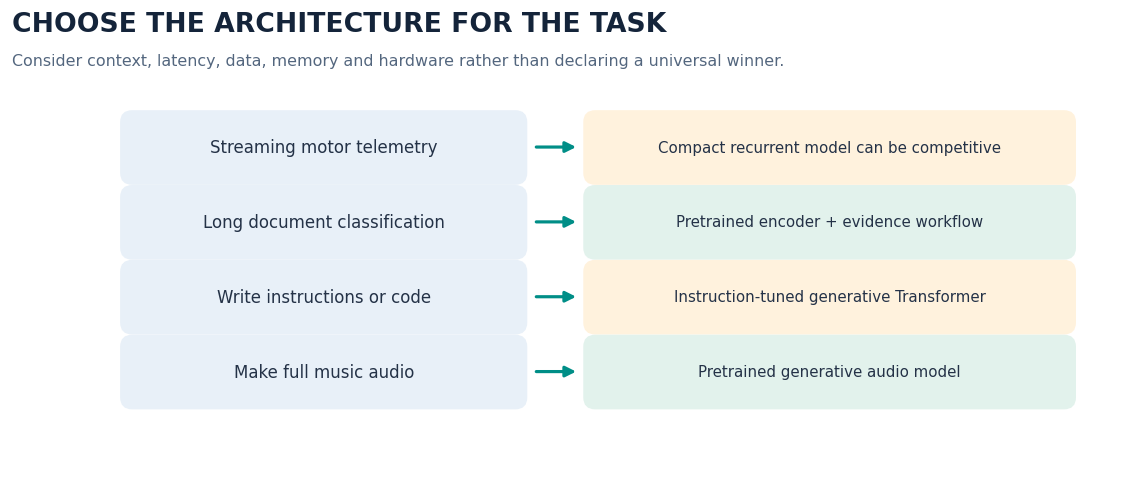

In [42]:
diagram('choices')  # This illustration is reproduced by the drawing helpers above.

### Final guided practical: choose, test and explain

Pick **one** of the following contexts:

**A. Campus information assistant:** Students ask where a workshop will take place. Use the extractive reader on a passage you write containing at least five concrete facts. Include one question whose answer is missing.

**B. Learning assistant:** Use the generative model to explain one AI concept from Weeks 1–6, first with a vague prompt and then with a carefully specified prompt. Evaluate clarity and correctness.

**C. Programming assistant:** Ask the generative model for a short Python function. Review and test it on at least two cases. Identify at least one case where a naive implementation could fail.

**Your evidence:** Save the prompt or passage, the model output, what you changed, and **3–5 sentences of your own interpretation**. A copied model response without interpretation does not demonstrate understanding.

Optional code workspace below:

In [43]:
# FINAL PRACTICAL — Task C: Programming assistant
# First ask the pretrained model to suggest a function. Inspect its output before
# deciding whether it is safe and correct. Do NOT execute generated text automatically.

my_task = 'C'
code_prompt = (
    'Write a short Python function average_mark(marks) that accepts a nonempty list '
    'of numeric marks and returns the arithmetic mean. Output only Python code.'
)
generated_code = generate_answer(code_prompt, max_new_tokens=150)
print('WHAT I ASKED THE MODEL TO DO:\n', code_prompt)
print('\nMODEL-GENERATED CODE (inspect manually; not executed automatically):\n')
print(generated_code)

# WHAT I CHANGED: I wrote a reviewed implementation separately instead of blindly
# executing the model output. It also handles an empty list explicitly.
def average_mark(marks):
    """Return the arithmetic mean of a nonempty list of numeric marks."""
    if not marks:
        raise ValueError("marks must not be empty")
    return sum(marks) / len(marks)

# WHAT HAPPENED: test at least two normal cases and one edge case.
tests = [
    ("three marks", [50, 70, 90], 70),
    ("one mark", [100], 100),
]
for label, marks, expected in tests:
    actual = average_mark(marks)
    print(f"{label}: average_mark({marks}) = {actual}; expected = {expected}; PASS = {actual == expected}")

try:
    average_mark([])
except ValueError as exc:
    print("empty-list edge case: handled explicitly ->", exc)
else:
    print("empty-list edge case: FAIL (expected ValueError)")

print("\nCompare the generated code above with the reviewed implementation.")
print("If you decide to test the generated version itself, first inspect it and copy it into a separate cell.")


WHAT I ASKED THE MODEL TO DO:
 Write a short Python function average_mark(marks) that accepts a nonempty list of numeric marks and returns the arithmetic mean. Output only Python code.

MODEL-GENERATED CODE (inspect manually; not executed automatically):

```python
def average_mark(marks):
    """
    Calculate the average of a list of marks.

    Parameters:
    marks (list): A list of numeric marks.

    Returns:
    float: The average of the marks.
    """
    if not marks:
        return 0.0

    total = sum(marks)
    count = len(marks)

    return total / count

# Example usage:
marks_list = [85, 92, 76, 88]
average = average_mark(marks_list)
print(f"The average mark is: {average}")
```

This Python function `average_mark` takes a list of marks as input and calculates their average using the formula for the arithmetic mean.
three marks: average_mark([50, 70, 90]) = 70.0; expected = 70; PASS = True
one mark: average_mark([100]) = 100.0; expected = 100; PASS = True
empty-list edge 

---
# REVIEW QUESTIONS - Answer in your own words

**These questions are deliberately not answered for you.** Use the notebook, the code output and your own examples. Aim for short but reasoned answers rather than memorised definitions.

**Q1. From LSTM to Transformer.** An LSTM receives a 100-word sentence one token at a time. Explain how it carries information forward. How is information exchanged differently in self-attention? Give one benefit and one trade-off of each architecture.

**Q2. Tokens and vectors.** Why does a language model need tokenization and numeric representations? Explain why a token is not necessarily a complete English word.

**Q3. Read the attention results.** In our toy example, the `she` row has three attention weights. What does one weight mean? Why do the weights across that row sum to 1? Why would it be incorrect to call these weights “probabilities that the sentence is true”?

**Q4. Q, K and V.** Without writing the equation, describe what happens in a self-attention calculation from the input representations to the output vectors. Explain which roles Query, Key and Value play.

**Q5. The masking challenge.** Consider the five-token sequence `The student opened the book`. Using positions numbered from 1, when a causal decoder processes token 4, which positions can token 4 attend to and which are hidden? Why?

**Q6. Reading versus writing.** Your extractive question-answering model returns `Laboratory B` from a university notice. Your generative model writes an entire paragraph about a university notice. Explain the architectural or task difference, and give one failure that either system could make.

**Q7. Temperature and reliability.** You rerun a generative model with a higher temperature and obtain a more surprising response. Has the model acquired new knowledge? Is the surprising response more likely to be factually correct? Justify.

**Q8. Architecture choice.** You need to predict motor temperature every second on a low-power device and separately answer questions from long course documents. Would you automatically use the same model for both? Explain which models or design approaches you would investigate and what measurements you would compare.

### Submission / reflection box

Write your answers in Markdown cells you insert below (or in a separate report). For the final practical, include evidence of **what you changed**, **what happened** and **what it means**. Running cells without interpreting their results is not the goal.

### Five things to remember

1. **RNNs/LSTMs:** learn with recurrent state and controlled memory.
2. **Self-attention:** calculates content-dependent weighted combinations of Value vectors using Query–Key matches.
3. **Transformers:** use attention alongside positional information, feed-forward layers, normalisation and residual connections.
4. **Pretrained generative models:** can create token sequences conditioned on prompts, without retraining their weights for every prompt.
5. **Engineering judgement:** test outputs, verify facts, consider cost and select architectures for the problem.

**Further reading:** *Artificial Intelligence Basics: Tutorial Notes and Guided Study*, Tutorials 15–18; the accompanying *From LSTM Memory to Transformer Attention and Generative AI* lecture. Optional official documentation: [Hugging Face Transformers](https://huggingface.co/docs/transformers/index), [DistilBERT QA model](https://huggingface.co/distilbert/distilbert-base-cased-distilled-squad), [Qwen2.5-0.5B-Instruct model](https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct), and [FLAN-T5-small](https://huggingface.co/google/flan-t5-small).

#  Review questions answered

## Q1. From LSTM to Transformer
An LSTM reads the sentence token by token and updates a hidden state and a cell state at each step; gates help it retain or discard information. In self-attention, each token compares its Query with the Keys of other tokens and combines their Value vectors, so information can move directly between positions in a layer. An LSTM can be efficient for streaming and has a naturally sequential state, but distant information must pass through recurrent steps. A Transformer offers more direct long-range interaction and parallel processing during training, but dense attention can use substantial memory and computation as the sequence grows.

## Q2. Tokens and vectors
Tokenization breaks text into units that the model's vocabulary can represent, and token IDs map those units to numbers. Embedding layers then represent the IDs as numeric vectors that can be transformed by neural-network operations. A token is not necessarily a complete English word because a tokenizer may split a rare or unfamiliar word into subword pieces, or may represent punctuation and spaces as separate tokens. The exact split depends on the tokenizer.

## Q3. Read the attention results
A weight in the `she` row tells how much the toy attention calculation uses the Value vector at one source-token position when building the output vector for `she`. The row sums to 1 because softmax converts the row's matching scores into nonnegative weights that are normalised to sum to one. These are not probabilities that the sentence is true: they are relative weights within this calculation, based on toy vectors and matrices, not truth estimates. A high weight also does not by itself prove a word is the correct reference.

## Q4. Q, K and V
The model first projects each input vector into three representations. A Query expresses what a token is matching for; Keys provide the representations it compares against; Values contain the information to combine. Query–Key dot products produce matching scores, scaling and softmax turn those scores into weights, and the weights mix the Value vectors into a new contextual vector for each token. In the notebook's toy example, the projection matrices are illustrative rather than learned.

## Q5. The masking challenge
With positions numbered from 1, token 4 (“the”) can attend to positions **1, 2, 3 and 4**. It cannot attend to position **5** (“book”), because that is a future token. A causal decoder hides future positions to prevent a next-token prediction from using the answer it is supposed to predict; later positions have more preceding context available.

## Q6. Reading versus writing
The extractive reader is trained to locate an answer span in the passage and return text from it, such as “Laboratory B.” The generative model predicts and produces a sequence of new tokens, so it can write a paragraph rather than selecting one span. The reader can return an irrelevant span when the answer is missing; the generator can invent plausible but unsupported details. Both outputs must be checked against evidence.

## Q7. Temperature and reliability
No. Raising temperature changes how the model selects among next-token options during sampling; it does not update the pretrained weights or give the model new knowledge. A more surprising response may be less predictable, but surprise is not evidence of factual correctness. I would compare the answer with trusted information and judge accuracy separately from creativity.

## Q8. Architecture choice
I would not automatically use the same model for both jobs. For second-by-second motor-temperature prediction on a low-power device, I would investigate a compact time-series model such as an LSTM/GRU, a small temporal convolution, or a simpler statistical baseline, measuring prediction error, latency, memory, power use and robustness to sensor noise. For questions over long course documents, I would investigate document retrieval plus a suitable Transformer reader or grounded generative model, measuring answer correctness, evidence support, coverage, response time and cost. The decision should follow tests on representative data and device constraints rather than the popularity of an architecture.

---

# practical — Task C: Programming assistant

**Chosen context:** Generate and verify a small Python function that calculates the average of a list of marks.

**Prompt used:** “Write a short Python function `average_mark(marks)` that accepts a nonempty list of numeric marks and returns the arithmetic mean. Output only Python code.”

**What I changed:** I kept the generated suggestion separate from the executable test code. Rather than blindly running model-generated text, I reviewed the logic and wrote a separate implementation that explicitly raises a `ValueError` for an empty list.

**What happened:** The notebook tests the reviewed function with `[50, 70, 90]`, which should return `70`, and `[100]`, which should return `100`. It also tests the empty-list edge case and expects a clear `ValueError`. The actual model-generated code is printed by the practical cell when the notebook is run in an environment where the pretrained model has loaded; its exact wording should be compared with the reviewed implementation rather than assumed to be correct.

**What it means:** The two normal cases check arithmetic with several values and with one value. The edge-case test checks that the function fails deliberately and clearly instead of attempting an invalid division. Passing these tests is useful evidence, but it does not prove that every possible input is handled; additional checks could cover non-numeric items, invalid types or very large inputs. The generated code should only be executed after its syntax and behaviour have been reviewed.

## Overall reflection
The toy attention experiment showed that attention weights are normalised relative contributions, not truth scores. The causal-mask experiment showed how a decoder prevents access to future tokens, and the pair-count experiment illustrated the quadratic growth of dense attention. The reading and generation activities demonstrate different tasks: one selects evidence from a passage while the other composes new tokens. In practical use, I should record the actual model outputs, compare them with the prompt or source text, test code rather than trusting its appearance, and report limitations instead of treating fluent output as proof.
